# Lab 3.1: Can One Attention Head Learn to Look Up an Answer?

This is the first LLM internals lab. We’ll open up one operation used in decoder-only Transformers and see whether it can learn to retrieve a value from a prompt. In the Lab 2.3 on LSTMs, information had to travel through each recurrent step. Here the query can directly read from earlier positions.

## 1. Calculate one attention row by hand

For each position, the query $q_i$ scores the visible keys $k_j$. Softmax turns those scores into coefficients $a_{ij}$, and the output is $sum_j a_{ij}v_j$. The matrices that project inputs into $Q$, $K$ and $V$ are parameters. The coefficients $a_{ij}$ are recomputed for every input.

Use four tokens with two coordinates each. Let $Q=K=X$ and let $V$ double the first coordinate and quadruple the second. For the second token, $q=[0,1]$. Its dot products with the first two keys are $0$ and $1$. Divide by $sqrt{2}$, mask the two future positions before softmax, and you get about $[0.330,0.670,0,0]$. Mixing the first two value vectors gives about $[0.660,2.679]$.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display
from torch import nn
from torch.nn import functional as F

sys.path.insert(0, str(Path("../lm-internals").resolve()))
from lm_lab import load_ckpt, save_ckpt

torch.manual_seed(31)
torch.set_num_threads(1)
CKPT = Path("checkpoints/lab31")
FIGS = Path("figures/lab31")
FIGS.mkdir(parents=True, exist_ok=True)

def causal_attention(q, k, v):
    length = q.size(-2)
    future = torch.ones(length, length, dtype=torch.bool, device=q.device).triu(1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
    weights = scores.masked_fill(future, -torch.inf).softmax(dim=-1)
    return weights @ v, weights

x = torch.tensor([[1., 0.], [0., 1.], [1., 1.], [-1., 1.]])
value_projection = torch.diag(torch.tensor([2., 4.]))
out, weights = causal_attention(x, x, x @ value_projection)

scale = math.exp(1 / math.sqrt(2))
expected = torch.tensor([2 / (1 + scale), 4 * scale / (1 + scale)])
torch.testing.assert_close(out[1], expected)
assert torch.count_nonzero(weights.triu(1)) == 0

edited = x.clone()
edited[-1] = torch.tensor([2., -3.])
edited_out, _ = causal_attention(edited, edited, edited @ value_projection)
torch.testing.assert_close(out[:-1], edited_out[:-1])
assert not torch.allclose(out[-1], edited_out[-1])
print("Second row:", weights[1].tolist())
print("Second output:", out[1].tolist())
print("Changing the last token changed its own output and left earlier outputs fixed.")

Second row: [0.3302384614944458, 0.6697615385055542, 0.0, 0.0]
Second output: [0.6604769229888916, 2.679046154022217]
Changing the last token changed its own output and left earlier outputs fixed.


That last property is **prefix invariance**. With fixed weights and position indices, a causal decoder gives a prefix the same outputs when you append more tokens. In a later lab we’ll use that property to reuse old keys and values during generation.

## 2. Teach the head to retrieve by content

Given `red=8 blue=2 green=0 ASK-blue`, predict `2` at the query position. Each color–digit pair is one token, so a single position can provide both a key for matching and a value to read. The order of the pairs changes, and every color can hold every digit. The head has no positional embeddings because the answer depends on the color queried.

We hold out whole red/blue/green digit triples whose sum is divisible by five, along with all their orderings and queries. This tests new combinations of familiar tokens. The training loop uses cross-entropy only at the query position. Every projection and the embedding table are learned through autograd.

In [2]:
COLORS = ("red", "blue", "green")
ORDERS = torch.tensor([[0, 1, 2], [0, 2, 1], [1, 0, 2],
                       [1, 2, 0], [2, 0, 1], [2, 1, 0]])
TRIPLES = torch.cartesian_prod(*(torch.arange(10) for _ in COLORS))
held_out = TRIPLES.sum(dim=-1) % 5 == 0
training_triples = TRIPLES[~held_out]
test_triples = TRIPLES[held_out]

def make_prompts(digits, order, query):
    pairs = 10 * order + digits.gather(1, order)
    tokens = torch.cat([pairs, (30 + query)[:, None]], dim=1)
    targets = digits.gather(1, query[:, None]).squeeze(1)
    return tokens, targets

class LookupHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(33, 16)
        self.query = nn.Linear(16, 16, bias=False)
        self.key = nn.Linear(16, 16, bias=False)
        self.value = nn.Linear(16, 16, bias=False)
        self.readout = nn.Linear(16, 10)

    def forward(self, tokens, uniform=False):
        x = self.embedding(tokens)
        values = self.value(x)
        mixed, weights = causal_attention(self.query(x), self.key(x), values)
        # Every token is visible to the final query, including the query itself.
        query_mix = values.mean(dim=1) if uniform else mixed[:, -1]
        return self.readout(query_mix), weights[:, -1]

model = LookupHead()
initial_state = {name: tensor.detach().numpy().copy()
                 for name, tensor in model.state_dict().items()}
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_trace = []
steps = 300

for _ in range(steps):
    digits = training_triples[torch.randint(len(training_triples), (128,))]
    order = ORDERS[torch.randint(len(ORDERS), (128,))]
    query = torch.randint(len(COLORS), (128,))
    tokens, targets = make_prompts(digits, order, query)
    logits, _ = model(tokens)
    loss = F.cross_entropy(logits, targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_trace.append(loss.item())

case = torch.cartesian_prod(torch.arange(len(test_triples)),
                            torch.arange(len(ORDERS)), torch.arange(len(COLORS)))
tokens, targets = make_prompts(test_triples[case[:, 0]], ORDERS[case[:, 1]], case[:, 2])
model.eval()
with torch.no_grad():
    logits, _ = model(tokens)
    uniform_logits, _ = model(tokens, uniform=True)

accuracy = (logits.argmax(dim=-1) == targets).float().mean().item()
uniform_accuracy = (uniform_logits.argmax(dim=-1) == targets).float().mean().item()
print(f"Test prompts: {len(tokens):,}")
print(f"Learned attention: {accuracy:.2%} | Uniform attention: {uniform_accuracy:.2%}")

Test prompts: 3,600
Learned attention: 100.00% | Uniform attention: 40.67%


## 3. Follow the answer when the prompt changes

Before running the cell, predict what happens when we change the query, edit the requested digit, or edit an unrelated digit. Which changes should move the attention? Which should move the answer? Every prompt below is drawn from the held-out split.

The uniform-attention run above is an **ablation**. It replaces the final query’s learned weighted sum with a plain average of the same value vectors, keeping the trained readout fixed. It measures how much this trained model depends on its learned weighting. The input edits below change a whole token, so they can affect both its key and its value.

Original             red=8 blue=2 green=0 ASK-blue      → 2 (target 2)
Switch query         red=8 blue=2 green=0 ASK-red       → 8 (target 8)
Edit requested digit red=8 blue=7 green=0 ASK-blue      → 7 (target 7)
Edit distractor      red=3 blue=2 green=0 ASK-blue      → 2 (target 2)


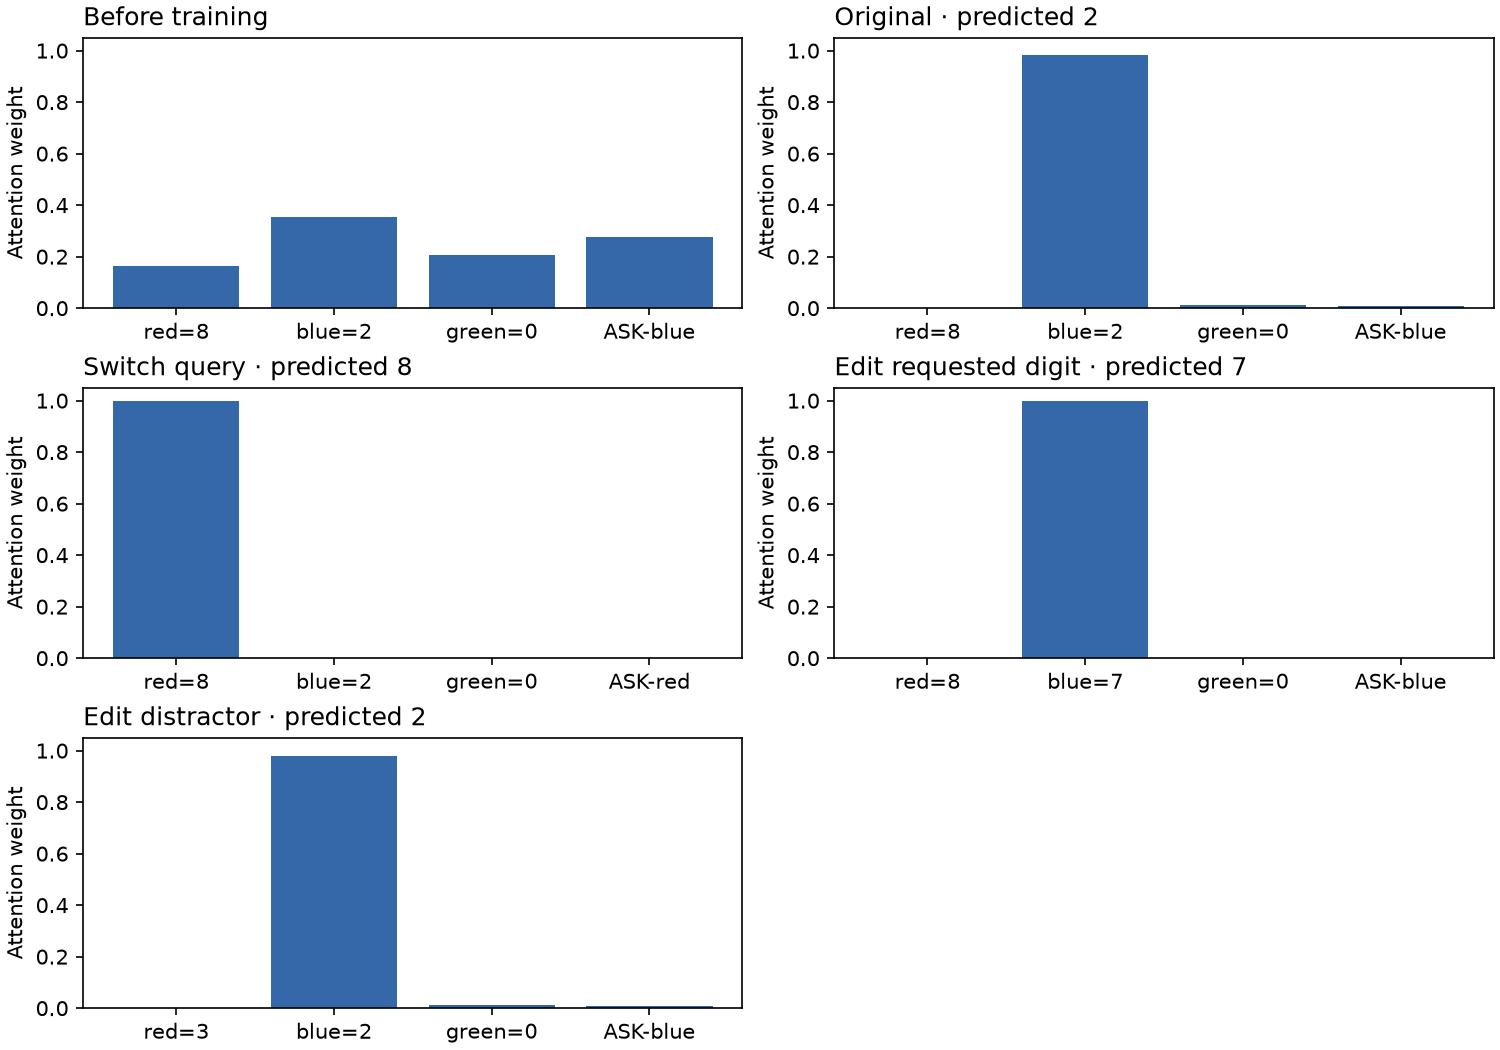

In [3]:
def token_label(token):
    if token >= 30:
        return f"ASK-{COLORS[token - 30]}"
    return f"{COLORS[token // 10]}={token % 10}"

# Adding five modulo ten keeps an edited triple in the test split.
digits = torch.tensor([[8, 2, 0], [8, 2, 0], [8, 7, 0], [3, 2, 0]])
queries = torch.tensor([1, 0, 1, 1])
assert (digits.sum(dim=-1) % 5 == 0).all()
prompts, answers = make_prompts(digits, ORDERS[0].expand(len(digits), -1), queries)

initial = LookupHead()
initial.load_state_dict({name: torch.from_numpy(array) for name, array in initial_state.items()})
with torch.no_grad():
    _, before = initial(prompts[:1])
    logits, after = model(prompts)

predicted = logits.argmax(dim=-1)
scenarios = ["Original", "Switch query", "Edit requested digit", "Edit distractor"]
for scenario, prompt, prediction, answer in zip(scenarios, prompts, predicted, answers):
    text = " ".join(token_label(token) for token in prompt.tolist())
    print(f"{scenario:20s} {text:34s} → {prediction.item()} (target {answer.item()})")

fig, axes = plt.subplots(3, 2, figsize=(10, 7), layout="constrained")
rows = [("Before training", prompts[0], before[0], None)]
rows += [(label, prompt, weights, prediction.item())
         for label, prompt, weights, prediction in zip(scenarios, prompts, after, predicted)]

for ax, (label, prompt, weights, prediction) in zip(axes.flat, rows):
    ax.bar(range(len(prompt)), weights.numpy(), color="#3568a9")
    ax.set_xticks(range(len(prompt)), [token_label(token) for token in prompt.tolist()])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Attention weight")
    title = label if prediction is None else f"{label} · predicted {prediction}"
    ax.set_title(title, loc="left")
axes.flat[-1].set_axis_off()
plot_path = FIGS / "query_attention.png"
fig.savefig(plot_path, dpi=150)
plt.close(fig)
display(Image(filename=str(plot_path)))

Compare the original prompt and the distractor edit. Did the output stay fixed even if some attention weights moved? Then compare the original and requested-digit edit. What does that pair tell you that the plot alone could never tell you? The uniform average still gets information from every token. Why might its accuracy be higher than guessing a digit uniformly?

## Save and reload

Save the starting weights and trained weights, then check that reloading the checkpoint gives the same logits on the four probe prompts.

In [4]:
save_ckpt(CKPT, "lookup_initial", step=0, **initial_state)
final_state = {name: tensor.detach().numpy() for name, tensor in model.state_dict().items()}
path = save_ckpt(CKPT, "lookup_trained", step=steps,
                 metrics={"test_accuracy": accuracy, "uniform_accuracy": uniform_accuracy},
                 train_loss=torch.tensor(loss_trace).numpy(), **final_state)

saved = load_ckpt(path)
saved.pop("train_loss")
restored = LookupHead()
restored.load_state_dict({name: torch.from_numpy(array) for name, array in saved.items()})
with torch.no_grad():
    restored_logits, _ = restored(prompts)
torch.testing.assert_close(restored_logits, logits)
print("Reloaded checkpoint reproduces the probe logits.")

Reloaded checkpoint reproduces the probe logits.


The next lab will reuse the causal head inside a decoder block and predict a next character at every position of a training sequence.

### Reproduce

From the repository root, run `cd labs/ml/llm-internals` and open
`01_one_head_content_lookup.ipynb` in Jupyter using the shared MNIST environment.
The notebook uses CPU and generates its own data.